# Tree tensor training

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from tree_tensor.tree_tensor_torch import TreeBasedTensor
from tree_cross.tree_cross_torch import TreeCross
from pde.coeff_function import coeff
from benchmarks.util import RMS
from tree_tensor_training.training import ARGS_tree_tensor_training, train

In [30]:
args = ARGS_tree_tensor_training(
  verbose = 1,
  Nx = 100,           # spatial resolution
  Ny = 10,            # parameter resolution
  Ny_decay = True,
  n_param = 100,       # number of parameters for diffusion coeff
  c_offset = 1,      # parameter mean
  c_var = 4,         # 'variance' of the parameters
  tree_type = 'balanced',
  N_train = int(1e5),
  N_test = int(1e3),
  optimizer = 'lstsq',
  epoch_outer = 20,
  eps = 1e-4,
  N_mc = 500,
)

cfun_np = coeff(args.Nx, args.Ny, args.c_offset, args.c_var, args.c_decay)
cfun = lambda x : torch.from_numpy(cfun_np(x))

In [31]:
stats, tensor = train(args, return_tensor=True)
tensor.tree.print()

Running tree tensor training...
ARGS_tree_tensor_training(verbose=1, Nx=100, Ny=10, Ny_decay=True, n_param=100, c_offset=1, c_var=4, c_decay=2.0, tree_type='balanced', tree_weight_decay=0.0, N_train=100000, N_test=1000, optimizer='lstsq', lr_start=0.01, lr_end=0.001, lr_factor=0.5, lr_patience=5, lr_threshold=0.001, init='mean', init_noise=0.01, rinit=20, epoch_outer=20, epoch_inner=2, rounding=False, eps=0.0001, lstsq_precondition=True, phys_reduction=True, round_start=0, extra_eps=0.1, cross_eps=0.0001, cross_niter=15, cross_kickrank=5, rng_seed=0, N_mc=500, device='cpu')
Cross approximation: RMS l2 err = 7.01e-04, size 233830, max rank 85, 12.8s
epoch 0, train loss 1.61e+00, validation loss 1.64e+00, lr 1.0e-02, size 258553, sweep 51.87s
epoch 1, train loss 1.52e+00, validation loss 1.79e+00, lr 1.0e-02, size 258553, sweep 50.55s
epoch 2, train loss 1.46e+00, validation loss 1.82e+00, lr 1.0e-02, size 258553, sweep 51.36s
epoch 3, train loss 1.42e+00, validation loss 1.82e+00, lr 1.

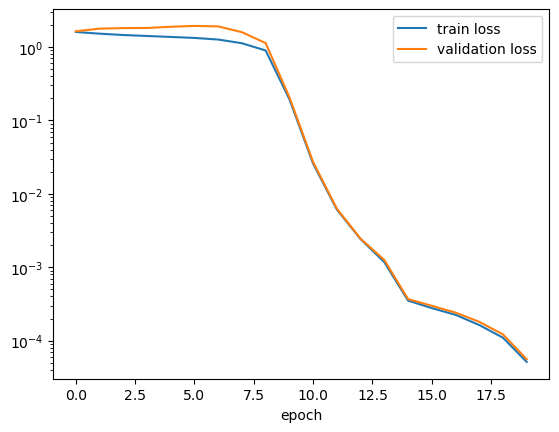

In [32]:
fig, ax = plt.subplots()
ax.plot(stats['train_loss'], label='train loss')
ax.plot(stats['test_loss'], label='validation loss')

ax.set_xlabel('epoch')
ax.set_yscale('log')
ax.legend()

## Comparison with cross approximation

In [33]:
rng = np.random.default_rng()

def err_MC(tensor, cfun, N_MC=500):
  errs = np.zeros(N_MC)
  for i in range(N_MC):
    # eval tree tensor approx of coeff at random parameter
    y = rng.integers(0, tensor.shape[1:])
    C_eval = torch.ravel(tensor[:, *y])

    X = np.hstack([np.arange(args.Nx).reshape((-1,1)), np.tile(y, [args.Nx,1])])
    C_true = cfun(X)

    errs[i] = RMS((C_eval-C_true).numpy(force=True))

  return errs

In [34]:
n_iter = 10
tol = 1e-4
kickrank = 2

C_a = TreeBasedTensor.randn(tensor.tree, tensor.shape, 10)
cross = TreeCross(C_a)

cross.run(cfun, n_iter=n_iter, eps=tol, kickrank=kickrank, random_kick=1, verbose=1)
C_a.round(tol=tol*.5)

swp:  1/10 f_evals=21215 self.max_dx=2.01e+06
swp:  2/10 f_evals=44196 self.max_dx=6.91e+00
swp:  3/10 f_evals=80275 self.max_dx=4.89e+00
swp:  4/10 f_evals=132726 self.max_dx=1.24e+00
swp:  5/10 f_evals=192946 self.max_dx=4.64e-01
swp:  6/10 f_evals=266846 self.max_dx=3.74e-01
swp:  7/10 f_evals=372265 self.max_dx=2.66e-01
swp:  8/10 f_evals=518132 self.max_dx=9.46e-02
swp:  9/10 f_evals=703469 self.max_dx=4.79e-02
swp: 10/10 f_evals=929916 self.max_dx=6.03e-02


In [35]:
err_cross = err_MC(C_a, cfun, args.N_mc)
err_train = err_MC(tensor, cfun, args.N_mc)

print(f'cross approximation: error {RMS(err_cross):.2e}, size {C_a.sparse_size}')
print(f'training:            error {RMS(err_train):.2e}, size {tensor.sparse_size}')

cross approximation: error 4.16e-03, size 155519
training:            error 7.71e-03, size 258553
